In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from CNN import run_cv
from plotting import plot_heatmap

# Load data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Select 10,000 images with stratified split
Xtr, _, ytr, _ = train_test_split(
    x_train, y_train,
    train_size=10000,
    stratify=y_train,
    random_state=2026
)

In [2]:
learning_rates = [1e-2, 1e-3, 1e-4]
dropouts = [0.0, 0.3, 0.6]

In [3]:
losses = np.zeros((len(learning_rates), len(dropouts)))

for i, lr in enumerate(learning_rates):
    for j, dropout in enumerate(dropouts):

        loss, best_epoch = run_cv(Xtr, ytr, lr=lr, dropout=dropout)
        losses[i, j] = loss

        print(f"LR={lr}, Dropout={dropout}: "
              f"val loss={loss:.4f}, best epoch={best_epoch}")


LR=0.01, Dropout=0.0, Kernel=3, Conv layers=2, Dense units=1024
Epoch 1: mean val loss = 1.3003
Epoch 2: mean val loss = 1.2455
Epoch 3: mean val loss = 1.2338
Epoch 4: mean val loss = 1.2300
Epoch 5: mean val loss = 1.2279
Epoch 6: mean val loss = 1.2588
Epoch 7: mean val loss = 1.2485
Epoch 8: mean val loss = 1.2292
Stopped at epoch 8, best epoch: 5
LR=0.01, Dropout=0.0: val loss=1.2279, best epoch=5

LR=0.01, Dropout=0.3, Kernel=3, Conv layers=2, Dense units=1024
Epoch 1: mean val loss = 0.9363
Epoch 2: mean val loss = 0.8759
Epoch 3: mean val loss = 0.8529
Epoch 4: mean val loss = 0.8465
Epoch 5: mean val loss = 0.8472
Epoch 6: mean val loss = 0.8496
Epoch 7: mean val loss = 0.8499
Stopped at epoch 7, best epoch: 4
LR=0.01, Dropout=0.3: val loss=0.8465, best epoch=4

LR=0.01, Dropout=0.6, Kernel=3, Conv layers=2, Dense units=1024
Epoch 1: mean val loss = 1.2574
Epoch 2: mean val loss = 1.2330
Epoch 3: mean val loss = 1.2030
Epoch 4: mean val loss = 1.1953
Epoch 5: mean val loss = 

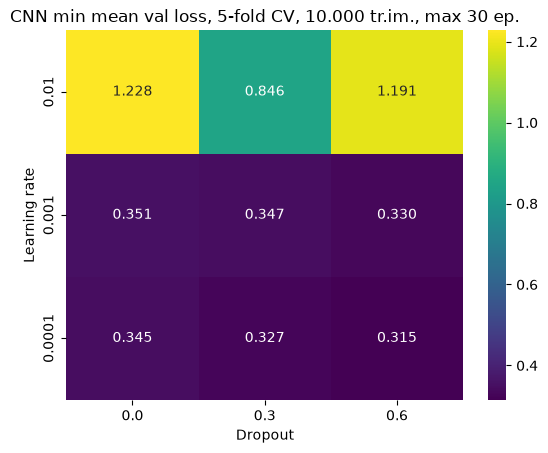

In [4]:
plot_heatmap(
    losses, dropouts, learning_rates,
    "Dropout", "Learning rate",
    title="CNN min mean val loss, 5-fold CV, 10.000 tr.im., max 30 ep."
)
plt.savefig("../figures/CNN_CV1.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
lr = 1e-4
dropout = 0.6
conv_layers = [1, 2]
kernel_size = [3, 5]

In [6]:
losses = np.zeros((len(conv_layers), len(kernel_size)))

for i, cl in enumerate(conv_layers):
    for j, ks in enumerate(kernel_size):

        loss, best_epoch = run_cv(Xtr, ytr, lr=lr, dropout=dropout, kernel_size=ks, conv_layers=cl, epochs=50)
        losses[i, j] = loss

        print(f"Conv. layers={cl}, Kernel size={ks}: "
              f"val loss={loss:.4f}, best epoch={best_epoch}")


LR=0.0001, Dropout=0.6, Kernel=3, Conv layers=1, Dense units=1024
Epoch 1: mean val loss = 0.5539
Epoch 2: mean val loss = 0.4808
Epoch 3: mean val loss = 0.4418
Epoch 4: mean val loss = 0.4188
Epoch 5: mean val loss = 0.4034
Epoch 6: mean val loss = 0.3897
Epoch 7: mean val loss = 0.3800
Epoch 8: mean val loss = 0.3699
Epoch 9: mean val loss = 0.3647
Epoch 10: mean val loss = 0.3566
Epoch 11: mean val loss = 0.3514
Epoch 12: mean val loss = 0.3509
Epoch 13: mean val loss = 0.3461
Epoch 14: mean val loss = 0.3427
Epoch 15: mean val loss = 0.3416
Epoch 16: mean val loss = 0.3378
Epoch 17: mean val loss = 0.3368
Epoch 18: mean val loss = 0.3348
Epoch 19: mean val loss = 0.3326
Epoch 20: mean val loss = 0.3350
Epoch 21: mean val loss = 0.3323
Epoch 22: mean val loss = 0.3303
Epoch 23: mean val loss = 0.3341
Epoch 24: mean val loss = 0.3325
Epoch 25: mean val loss = 0.3323
Stopped at epoch 25, best epoch: 22
Conv. layers=1, Kernel size=3: val loss=0.3303, best epoch=22

LR=0.0001, Dropout

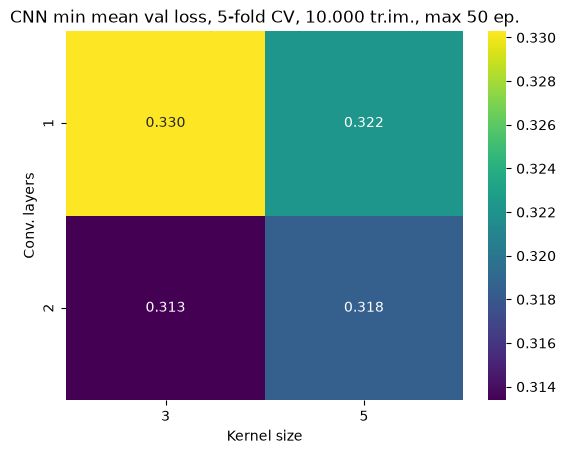

In [7]:
plot_heatmap(
    losses, kernel_size, conv_layers,
    "Kernel size", "Conv. layers",
    title="CNN min mean val loss, 5-fold CV, 10.000 tr.im., max 50 ep."
)

plt.savefig("../figures/CNN_CV_architecture.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [8]:
lr = 1e-4
dropout = 0.6
conv_layers = 2
kernel_size = 3
dense_units = [128, 256, 512, 1024]

In [9]:
losses = []
best_epochs = []

for units in dense_units:
    loss, best_epoch = run_cv(Xtr, ytr, lr=lr, dropout=dropout, kernel_size=kernel_size, conv_layers=conv_layers, dense_units=units, epochs=50)

    losses.append(loss)
    best_epochs.append(best_epoch)

    print(f"Dense units={units}: val loss={loss:.4f}, best epoch={best_epoch}")


LR=0.0001, Dropout=0.6, Kernel=3, Conv layers=2, Dense units=128
Epoch 1: mean val loss = 0.8498
Epoch 2: mean val loss = 0.6559
Epoch 3: mean val loss = 0.5842
Epoch 4: mean val loss = 0.5450
Epoch 5: mean val loss = 0.5124
Epoch 6: mean val loss = 0.4893
Epoch 7: mean val loss = 0.4716
Epoch 8: mean val loss = 0.4533
Epoch 9: mean val loss = 0.4443
Epoch 10: mean val loss = 0.4327
Epoch 11: mean val loss = 0.4244
Epoch 12: mean val loss = 0.4159
Epoch 13: mean val loss = 0.4109
Epoch 14: mean val loss = 0.4026
Epoch 15: mean val loss = 0.3965
Epoch 16: mean val loss = 0.3944
Epoch 17: mean val loss = 0.3861
Epoch 18: mean val loss = 0.3839
Epoch 19: mean val loss = 0.3803
Epoch 20: mean val loss = 0.3741
Epoch 21: mean val loss = 0.3687
Epoch 22: mean val loss = 0.3701
Epoch 23: mean val loss = 0.3644
Epoch 24: mean val loss = 0.3603
Epoch 25: mean val loss = 0.3597
Epoch 26: mean val loss = 0.3531
Epoch 27: mean val loss = 0.3520
Epoch 28: mean val loss = 0.3510
Epoch 29: mean val 

In [10]:
from tensorflow import keras
from CNN import make_model
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Best hyperparameters from CV
lr = 1e-4
dropout = 0.6
kernel_size = 3
conv_layers = 2
dense_units = 1024
epochs = 31

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Load all 60,000 training and 10,000 test images
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize using training statistics only
mean, std = x_train.mean(), x_train.std()
X_train = ((x_train - mean) / std).astype("float32")[..., None]
X_test = ((x_test - mean) / std).astype("float32")[..., None]

# Make final model
keras.utils.set_random_seed(2026) # Make sure we get reproducible model initialization and training
model = make_model(lr, dropout, kernel_size, conv_layers, dense_units)

In [11]:
#Train final model
model.fit(X_train, y_train, epochs=epochs, batch_size=64, verbose=1)

Epoch 1/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 22ms/step - accuracy: 0.7917 - loss: 0.5829
Epoch 2/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.8630 - loss: 0.3845
Epoch 3/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.8790 - loss: 0.3351
Epoch 4/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.8911 - loss: 0.3033
Epoch 5/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.8986 - loss: 0.2825
Epoch 6/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - accuracy: 0.9049 - loss: 0.2630
Epoch 7/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - accuracy: 0.9097 - loss: 0.2495
Epoch 8/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.9137 - loss: 0.2362
Epoch 9/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.9171 - loss: 0.2250
Epoch 10/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - accuracy: 0.9219 - loss: 0.2151
Epoch 11/31
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - accuracy: 0.9255 - loss: 0.2054
Epoch 12/31
938/938 ━━━━━━━━━━

Test accuracy: 0.9245 ± 0.0026
Parameter count: 3,241,354

Per-class metrics:
              precision    recall  f1-score   support

 T-shirt/top     0.8905    0.8460    0.8677      1000
     Trouser     0.9970    0.9850    0.9909      1000
    Pullover     0.9414    0.8360    0.8856      1000
       Dress     0.9249    0.9360    0.9304      1000
        Coat     0.8497    0.9160    0.8816      1000
      Sandal     0.9860    0.9880    0.9870      1000
       Shirt     0.7447    0.8140    0.7778      1000
     Sneaker     0.9786    0.9620    0.9702      1000
         Bag     0.9929    0.9810    0.9869      1000
  Ankle boot     0.9637    0.9810    0.9722      1000

    accuracy                         0.9245     10000
   macro avg     0.9270    0.9245    0.9251     10000
weighted avg     0.9270    0.9245    0.9251     10000



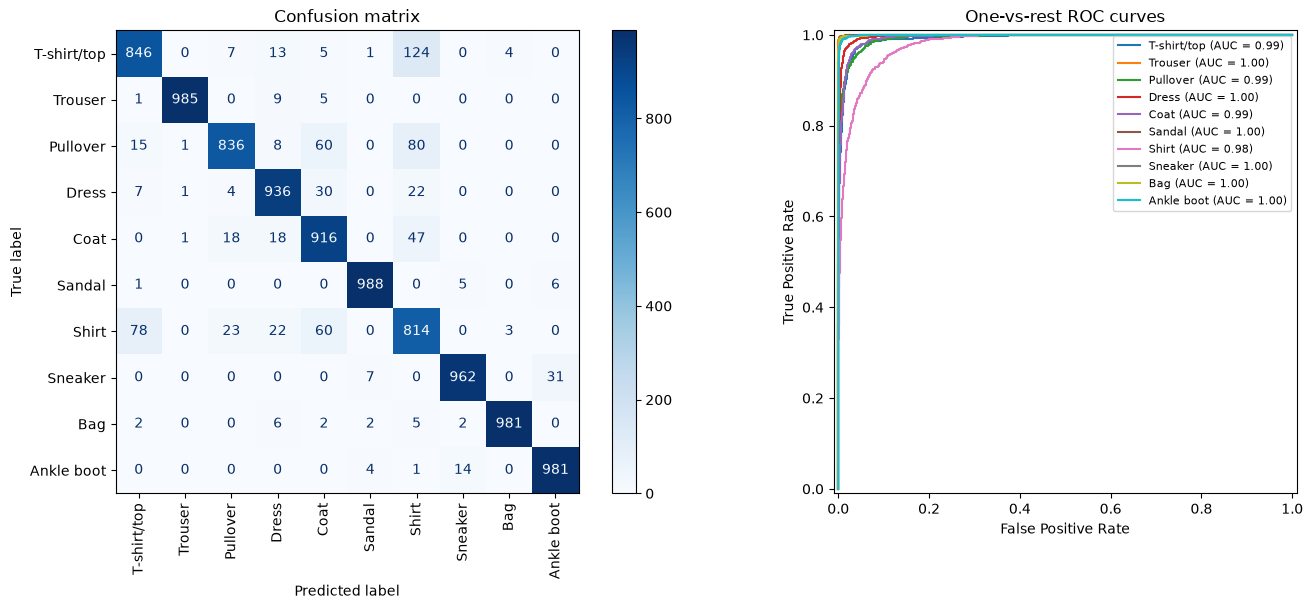

In [12]:
# Evaluate on test set ONCE

probs = keras.activations.softmax(model.predict(X_test, verbose=0)).numpy()
y_pred = probs.argmax(axis=1)

# Accuracy ± standard error
acc = accuracy_score(y_test, y_pred)
se = np.sqrt(acc * (1 - acc) / len(y_test))

print(f"Test accuracy: {acc:.4f} ± {se:.4f}")
print(f"Parameter count: {model.count_params():,}")

# Per-class F1 scores
print("\nPer-class metrics:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# Confusion matrix and one-vs-rest ROC/AUC
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names,
    ax=ax[0], xticks_rotation=90, cmap="Blues"
)
ax[0].set_title("Confusion matrix")

for i, name in enumerate(class_names):
    RocCurveDisplay.from_predictions(
        (y_test == i).astype(int), probs[:, i],
        name=name, ax=ax[1]
    )

ax[1].set_title("One-vs-rest ROC curves")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../figures/CNN_CV_final_results.png",
            dpi=300, bbox_inches="tight")
plt.show()